In [234]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
import matplotlib.patheffects as pe

In [2]:
def kroupa_imf(m_star,alpha0 = 0.3,alpha1 = 1.3,alpha2 = 2.3, alpha3=2.3):
    """
    Kroupa (2001) IMF: dN/dM, up to an arbitrary normalization.

    """
    m = np.asarray(m_star, dtype=float)

    xi = np.zeros_like(m)

    # Kroupa slopes
    # alpha0 = 0.3
    # alpha1 = 1.3
    # alpha2 = 2.3

    # Continuity factors
    A0 = 1.0

    # Continuity at 0.08 Msun
    A1 = A0 * 0.08**(alpha1 - alpha0)

    # Continuity at 0.5 Msun
    A2 = A1 * 0.5**(alpha2 - alpha1)

    # Continuity at 1.0 Msun
    A3 = A2 * 1.0**(alpha3 - alpha2)

    mask0 = (m >= 0.01) & (m < 0.08)
    mask1 = (m >= 0.08) & (m < 0.5)
    mask2 = (m >= 0.5) & (m < 1.0)
    mask3 = m >= 1.0

    xi[mask0] = A0 * m[mask0]**(-alpha0)
    xi[mask1] = A1 * m[mask1]**(-alpha1)
    xi[mask2] = A2 * m[mask2]**(-alpha2)
    xi[mask3] = A3 * m[mask3]**(-alpha3)

    return xi

In [5]:
def fulton_a(a, beta = -0.86,a0 = 3.6,gamma = 1.58):

    return (
        a**beta
        * (1 - np.exp(-(a / a0)**gamma))
    )

In [6]:
def power_law(x,A,alpha):

    return A*(x)**alpha
def e_frac_vs_mass(q, A=1.90896563,alpha=0.27628889):
    # a=0.08509622694638502
    # b=1.0913245932397357
    # A=0.09099884
    # alpha=0.52510921
    # c=0.1017109
    #return a * np.log10(q) + b
    
    
    return power_law(q,A,alpha)

In [113]:

def power_integral(lower, upper, exponent):
    """Integral of x**exponent between two positive bounds."""
    p = exponent + 1

    if abs(p) < 1e-10:
        return np.log(upper / lower)

    return (upper**p - lower**p) / p

In [114]:
def imf_moment(s, m_min=0.01, m_max=1000.0,
               alphas=gammas):
    """
    Normalized s-th moment of the Kroupa IMF.

    Stellar masses are expressed in solar masses.
    Returns a dimensionless quantity.
    """
    a0, a1, a2, a3 = alphas

    # Enforce continuity at each IMF breakpoint
    coeffs = np.array([
        1.0,
        0.08**(a1 - a0),
        0.08**(a1 - a0) * 0.5**(a2 - a1),
        0.08**(a1 - a0) * 0.5**(a2 - a1)
            * 1.0**(a3 - a2)
    ])

    numerator = 0.0
    denominator = 0.0

    for i in range(4):
        lo = max(m_min, breaks[i])
        hi = min(m_max, breaks[i + 1])

        if lo >= hi:
            continue

        numerator += coeffs[i] * power_integral(
            lo, hi, s - alphas[i]
        )

        denominator += coeffs[i] * power_integral(
            lo, hi, -alphas[i]
        )

    if denominator <= 0:
        raise ValueError("Invalid stellar mass range")

    return numerator / denominator

In [ ]:
def get_a_avg(a,beta = -0.86,a0 = 3.6,gamma = 1.58):
    
    return np.trapz(fulton_a(a, beta,a0,gamma), x=a)/np.trapz(fulton_a(a, beta, a0, gamma)/a, x=a)

In [116]:
get_a_avg(np.linspace(0.03,30,1000))

4.9377277744736805

In [ ]:
def analytic_mass_fraction(
    gammas,
    m_star_min=0.01,
    m_star_max=1000,
    m_planet=M_J,
    s=s,
    alpha=alpha_ej,
    A=A,
    a_min=0.03,
    a_max=30,
    a_planet=None,
    
):
    if a_planet is not None:
        avg_a=a_planet
    else:
        a_arr = np.linspace(a_max,  a_min, 1000)
        if m_planet<3.00274e-6*30:
            avg_a=(a_max-a_min)/np.log(a_max/a_min)
        else:
            avg_a = get_a_avg(a_arr)
    coeff = 1e-4 * A * 333030
    mu_imf=imf_moment(
            s,
            m_min=m_star_min,
            m_max=m_star_max,
            alphas=gammas
        )

    return (
        coeff * avg_a
        * mu_imf
        * m_planet**alpha
    )

In [196]:
analytic_mass_fraction(gammas)

0.39036480282655056
4.9377277744736805


17.940621234573523

In [ ]:
gamma_errors = np.array([0.7, 0.5/1.96, 0.3/2.57, 0.7/2.57])

In [171]:
gamma_errors = np.array([0.7, 0.5, 0.3, 0.7])

In [172]:

rng = np.random.default_rng(42)


N = 100_000

samples = rng.normal(
    loc=gammas,
    scale=gamma_errors,
    size=(N, len(gammas))
)

rho_samples = np.array([
    analytic_mass_fraction(g)
    for g in samples
])

rho_central = analytic_mass_fraction(gammas)

lower, median, upper = np.percentile(
    rho_samples, [16, 50, 84]
)

print("Nominal density:", rho_central)
print("Median density:", median)
print("68% interval:", lower, upper)
print("Asymmetric errors:",
      median - lower, upper - median)

Nominal density: 17.61547609477664
Median density: 18.41345396712248
68% interval: 11.637792844050491 34.70249426048769
Asymmetric errors: 6.775661123071988 16.28904029336521


In [145]:

def analytic_imf_error(gammas, sigma_gammas, alpha,
                       edges=breaks):

    gammas = np.asarray(gammas, dtype=float)
    sigma_gammas = np.asarray(sigma_gammas, dtype=float)
    edges = np.asarray(edges, dtype=float)

    n = len(gammas)
    s = 1 - alpha

    # Integral of M^q and derivative with respect to q
    def I(q, a, b):
        t = q + 1

        if abs(t) < 1e-8:
            return np.log(b / a)

        return (b**t - a**t) / t

    def dI(q, a, b):
        t = q + 1

        if abs(t) < 1e-6:
            return (np.log(b)**2 - np.log(a)**2) / 2

        return (
            t * (b**t * np.log(b) - a**t * np.log(a))
            - (b**t - a**t)
        ) / t**2

    # Piecewise continuity coefficients
    k = np.ones(n)

    for i in range(1, n):
        k[i] = k[i-1] * edges[i]**(
            gammas[i] - gammas[i-1]
        )

    # Derivatives of log(k_i) with respect to gamma_j
    dlogk = np.zeros((n, n))

    for i in range(1, n):
        for j in range(n):
            dlogk[i, j] = dlogk[i-1, j]

        dlogk[i, i] += np.log(edges[i])
        dlogk[i, i-1] -= np.log(edges[i])

    # Numerator and denominator of IMF moment
    N = 0.0
    D = 0.0

    dN = np.zeros(n)
    dD = np.zeros(n)

    for i in range(n):
        a, b = edges[i], edges[i+1]

        qN = s - gammas[i]
        qD = -gammas[i]

        IN = I(qN, a, b)
        ID = I(qD, a, b)

        N += k[i] * IN
        D += k[i] * ID

        # Include normalization-coefficient derivatives
        dN += k[i] * IN * dlogk[i]
        dD += k[i] * ID * dlogk[i]

        # Direct derivative of the exponent
        dN[i] -= k[i] * dI(qN, a, b)
        dD[i] -= k[i] * dI(qD, a, b)

    moment = N / D

    # Exact analytic gradient
    gradient = (dN * D - N * dD) / D**2

    # First-order uncertainty propagation
    sigma_moment = np.sqrt(
        np.sum((gradient * sigma_gammas)**2)
    )

    # Logarithmic uncertainty propagation
    sigma_log = sigma_moment / moment

    lower = moment * np.exp(-sigma_log)
    upper = moment * np.exp(sigma_log)

    return moment, sigma_moment, lower, upper, gradient

In [146]:
moment, sigma_moment, lower, upper, gradient=analytic_imf_error(gammas,gamma_errors,alpha_ej)

/var/folders/vk/2xktddx11s99wx6wl7rlmm9c0000gn/T/ipykernel_46325/4255155277.py:27: RuntimeWarning: invalid value encountered in scalar multiply
  t * (b**t * np.log(b) - a**t * np.log(a))


In [147]:
alpha_nominal = np.array([0.3, 1.3, 2.3, 2.3])
alpha_errors = np.array([0.7, 0.5, 0.3, 0.7])

s = 1 - 0.27628889
step = 1e-4

R = imf_moment(s, alphas=alpha_nominal)

variance = 0.0

for i in range(4):
    upper = alpha_nominal.copy()
    lower = alpha_nominal.copy()

    upper[i] += step
    lower[i] -= step

    deriv = (
        imf_moment(s, alphas=upper)
        - imf_moment(s, alphas=lower)
    ) / (2 * step)

    variance += (deriv * alpha_errors[i])**2

sigma_R = np.sqrt(variance)

print(f"R = {R:.4f} ± {sigma_R:.4f}")

R = 0.3904 ± 0.2049


In [148]:
a_arr=np.linspace(0.03,30,1000)
avg_a=get_a_avg(a_arr)
coeff=1e-4*A*333030
coeff*avg_a*moment*M_J**alpha_ej

18.05881023275773

In [149]:
alpha_nominal=alpha_ej

In [182]:
M_J=0.0009546
m_planet=M_J
gammas = np.array([0.3, 1.3, 2.3, 2.3])

# Published uncertainty ranges (not uniformly 1 sigma)
gamma_errors = np.array([0.7, 0.5/1.96, 0.3/2.57, 0.7/2.57])

# IMF boundaries, in solar masses
breaks = np.array([0.01, 0.08, 0.5, 1.0, np.inf])

# Ejection-fraction power-law exponent
alpha_ej = 0.27628889
s = 1 - alpha_ej

A=1.90896563

In [186]:
M_J**alpha_ej*1e-4*333030*A

9.307642240406157

In [155]:
edges = np.array([0.01, 0.08, 0.5, 1.0, 1000.0])

moment, sigma_moment, lower, upper, gradient = analytic_imf_error(
    gammas, gamma_errors, alpha_ej, edges=edges
)

In [158]:
rho_analytic = (
    coeff * avg_a * moment * m_planet**alpha_ej
)

rho_mc_nominal = analytic_mass_fraction(gammas)

print(rho_analytic, rho_mc_nominal)
lower_value=coeff * avg_a * lower * m_planet**alpha_ej
upper_value=coeff * avg_a * upper * m_planet**alpha_ej
print(lower_value, upper_value)

17.940621234573523 17.940621234573523
13.559691220915497 23.73696310915694


In [157]:
print(rho_analytic-upper_value,rho_analytic-lower_value)

-5.796341874583415 4.380930013658027


In [168]:
17.94*0.08

1.4352

In [201]:
mass_ratios=np.logspace(-6,-1,100)

a_planet=np.logspace(-1,2,100)
m_star=np.logspace(-1,1,100)
planet_masses=np.logspace(-5,-2,100)

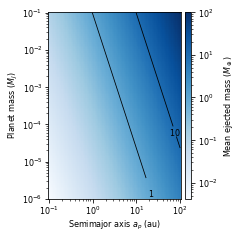

In [210]:
# Use existing planet_masses and a_planet arrays
cm=1/2.54
Z = np.zeros((len(mass_ratios), len(a_planet)))

for i, mp in enumerate(mass_ratios):
    for j, ap in enumerate(a_planet):
        Z[i, j] = ap*e_frac_vs_mass(
            q=mp
        )

# Convert planet masses from solar masses to Jupiter masses


fig, ax = plt.subplots(figsize=(8.7*cm, 8.7*cm))

mesh = ax.pcolormesh(
    a_planet,
    mass_ratios,
    Z,
    shading="auto",
    cmap="Blues",
    norm=LogNorm()
)

cbar = fig.colorbar(
    mesh, ax=ax,
    fraction=0.075,
    pad=0.03,
    aspect=30
)

cbar.set_label(r"Mean ejected mass ($M_\oplus$)", fontsize=8)
cbar.ax.tick_params(labelsize=8)

# Constant-ejected-mass contours
contours = ax.contour(
    a_planet,
    mass_ratios,
    Z,
    levels=np.logspace(0, 2, 3),
    colors="black",
    linewidths=0.8
)

ax.clabel(contours, fmt=r"$%g$", fontsize=8)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(r"Semimajor axis $a_p$ (au)", fontsize=8, labelpad=2)
ax.set_ylabel(r"Planet mass ($M_J$)", fontsize=8, labelpad=2)

ax.tick_params(axis="both", which="major", pad=2, labelsize=8)

plt.tight_layout()

In [212]:
star_masses=np.logspace(-1,1,100)

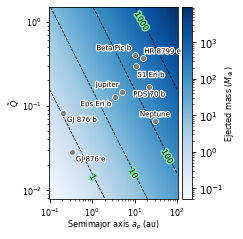

In [280]:
alpha = alpha_ej

# All combinations of existing stellar and planetary masses
MS, MP = np.meshgrid(star_masses, planet_masses)

# Both masses are in solar masses
Q_tilde = MP**alpha * MS**(1 - alpha)

# Define a regular grid spanning the effective coordinate
q_grid = np.logspace(
    np.log10(Q_tilde.min()),
    np.log10(Q_tilde.max()),
    200
)

# Existing semimajor-axis array
Z = np.zeros((len(q_grid), len(a_planet)))

# Evaluate the individual-system analytic model
for i, qt in enumerate(q_grid):
    for j, ap in enumerate(a_planet):
        Z[i, j] = 1e-4 * A * 333030 * qt * ap

fig, ax = plt.subplots(figsize=(8.7*cm, 8.7*cm))

mesh = ax.pcolormesh(
    a_planet,
    q_grid,
    Z,
    shading="auto",
    cmap="Blues",
    norm=LogNorm()
)

cbar = fig.colorbar(mesh, ax=ax, fraction=0.075, pad=0.03)
cbar.set_label(r"Ejected mass ($M_\oplus$)", fontsize=8, labelpad=0)

# contours = ax.contour(
#     a_planet,
#     q_grid,
#     Z,
#     levels=np.logspace(0, 2, 3),
#     colors="black",
#     linewidths=0.8
# )
label_locations=[(1,10**-1.9),(10,10**-1.9),(10**1.8,10**-1.9),(10**1.1,1)]

levels = [1, 10, 100, 1000]
spacings = [-5, 5, 5, 5]


for level, spacing, pos in zip(levels, spacings, label_locations):
    contour = ax.contour(
        a_planet,
        q_grid,
        Z,
        levels=[level],
        colors="black",
        linewidths=0.8,
        linestyles='dashed'
    )

    labels = ax.clabel(
    contour,
    fmt={level: rf"${level}$"},
    fontsize=8,
    inline=False,
    manual=[pos]
    )

    labels[0].set_path_effects([
        pe.withStroke(linewidth=3, foreground="#7AE6A2")
    ])
    labels[0].set_rotation(-60)

# labels=ax.clabel(contours, fontsize=8, manual=label_locations, inline_spacing=1)
# for label in labels:
#     label.set_rotation(-60)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(r"Semimajor axis $a_p$ (au)", fontsize=8, labelpad=0)
ax.set_ylabel(r"$\tilde{Q}$", fontsize=8, labelpad=0)

ax.tick_params(axis="both", labelsize=8)

# (stellar mass in Msun, planet mass in Mj, semimajor axis in au)
systems = {
    "Jupiter":       (1.00, 1.0, 5.20),
    "Neptune":       (1.00, 0.0540, 30.1),
    "GJ 876 b":      (0.33, 2.28, 0.208),
    "GJ 876 e":      (0.33, 0.046, 0.334),
    "PDS 70 b":      (0.76, 3.2, 22.0),
    "HR 8799 e":     (1.47, 10.0, 16.0),
    "Beta Pic b":    (1.75, 8.7, 10.3),
    "Eps Eri b":     (0.82, 1.0, 3.5),
    "51 Eri b":      (1.55, 4.1, 11.1),
}

# Label offsets in points: (dx, dy)
label_positions = {
    "Jupiter":       (-4, 4),
    "Neptune":       (0, 4),
    "GJ 876 b":      (4, -4),
    "GJ 876 e":      (4, -4),
    "PDS 70 b":      (0, -4),
    "HR 8799 e":     (1, 4),
    "Beta Pic b":    (-4, 4),
    "Eps Eri b":     (-4, -4),
    "51 Eri b":      (1, -6),
}

alpha = alpha_ej

systems_qtilde = {
    name: (
        ap,
        (mp / 1047.57)**alpha * ms**(1 - alpha)
    )
    for name, (ms, mp, ap) in systems.items()
}

for name, (ap, qt) in systems_qtilde.items():

    ax.scatter(
        ap, qt,
        s=35,
        color="grey",
        edgecolor="white",
        linewidth=0.8,
        zorder=5
    )

    dx, dy = label_positions[name]

    ha = "left" if dx > 0 else "right" if dx < 0 else "center"
    va = "bottom" if dy > 0 else "top" if dy < 0 else "center"

    txt = ax.annotate(
        name,
        (ap, qt),
        xytext=(dx, dy),
        textcoords="offset points",
        ha=ha,
        va=va,
        fontsize=7,
        color="black",
        zorder=6
    )

    txt.set_path_effects([
        pe.withStroke(linewidth=2.5, foreground="white")
    ])

plt.tight_layout()
plt.savefig('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Visualizations/Q_tilde_planet_heatmap.png', dpi=500,bbox_inches='tight',facecolor='white')